In [53]:
import cPickle as pickle
import os

import numpy as np
import matplotlib
# matplotlib.use("Agg")
import matplotlib.pyplot as plt
from twpca import TWPCA
from twpca.regularizers import curvature

import soundsig
from soundsig.sound import spectrogram, plot_spectrogram
from soundsig.signal import lowpass_filter, highpass_filter

import config
from spikes.plotting import raster
from segment_analysis import MultiSegment
from segment_analysis.timewarp import WindowedTimeWarp

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
BIRD_NAME = "LbY6074"
BIRD = "LbY6074__161215_145633"

In [4]:
DATADIR = config.DATADIR
data_path = os.path.join(DATADIR, "birds", BIRD_NAME, BIRD, "spikes", "{}-sorted.pkl".format(BIRD))

In [5]:
with open(data_path, "rb") as datafile:
    block = pickle.load(datafile)
block.create_relationship(recursive=True, force=True, append=True)

In [6]:
align4 = [0, 7, 16, 80]  # segments that play 4 motifs
align3 = [1, 9, 11, 19, 21, 68, 69, 71, 73, 74, 82, 95, 97, 98]  # segments that play 3 motifs
align2 = [2, 3, 4, 5, 8, 10, 12, 13, 17, 18, 20, 22, 67, 72, 85, 92, 93, 94, 99]  # segments that play 2 motifs

In [7]:
print len(align4), len(align3)

4 14


In [14]:
iters = 100
window = 40000
overlap = 20000

## Response to tutor song

Example tutor song shown

* Spikes convolved with gaussian with width std=0.4ms

* N=18 songs


In [8]:
multiseg = MultiSegment(np.array(block.segments)[align3 + align4])
print multiseg

MultiSegment with 18 Segments, 13 Units, t_start=-0.0s, t_stop=4.9692s
{'vocalization_type': 'unknown', 'sound_type': 'live', 'vocalizer': 'unknown', 'playback_file': None}


In [10]:
fs = np.round(multiseg.segments[0].analogsignals[0].sampling_rate.item())
times, analogsignals = zip(*[multiseg.get_analogsignal(s, 0, channel=0)[:2] for s in multiseg.segments])
minlen = np.min([s.size for s in analogsignals])
cut_analogsignals = np.array([s[:minlen] for s in analogsignals])

In [12]:
sigs = np.zeros((len(analogsignals), minlen))
for i, signal in enumerate(analogsignals):
    signal = np.copy(signal)
    signal -= np.mean(signal)
    signal[:] = highpass_filter(signal, fs, 2000)
    signal[:] = np.abs(lowpass_filter(signal, fs, 4800))
    signal[:] = lowpass_filter(signal, fs, 100)
    sigs[i, :minlen] = lowpass_filter(signal, fs, 100)[:minlen]

In [28]:
tutor_amp_envelope = np.copy(sigs)

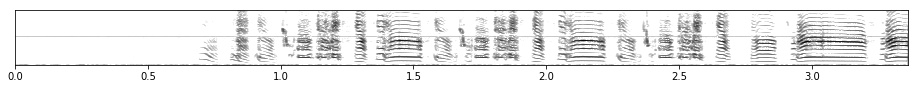

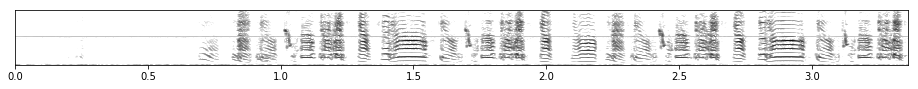

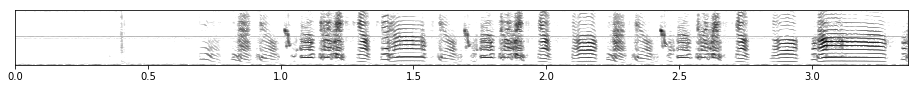

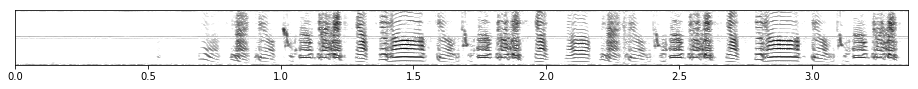

In [65]:
for signal in cut_analogsignals[:4]:
    fig, ax = plt.subplots(figsize=(16, 1))
    t, f, s, _ = spectrogram(signal - np.mean(signal), fs, 5000, 50.0, min_freq=0, max_freq=10000, nstd=6)
    plot_spectrogram(t, f, s, colormap="gray_r", ax=ax, colorbar=False)
    plt.ylabel("")
    plt.xlabel("")
    plt.yticks([])
    plt.show()

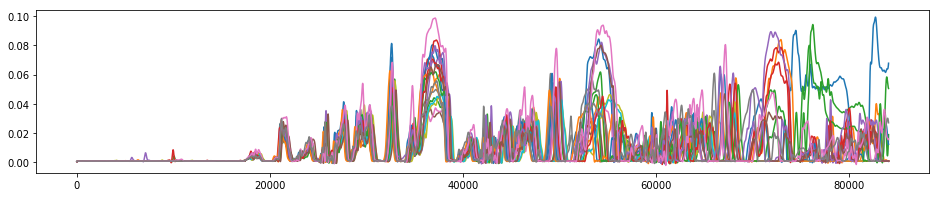

In [31]:
plt.figure(figsize=(16, 3))
for signal in tutor_amp_envelope:
    plt.plot(signal)
plt.show()

## Warp data by amplitude envelope

In [34]:
tutor_timewarped = WindowedTimeWarp(
    n_components=1,
    warptype="affine",
    warpinit="zero",
    warp_regularizer=curvature(scale=0.00001, power=1),
    time_regularizer=curvature(scale=0.00001, power=1, axis=0)
)

In [35]:
data = tutor_timewarped.fit_transform(tutor_amp_envelope[:, :, None], 40000, 20000, lr=2e-2, niter=iters)

100%|██████████| 100/100 [00:03<00:00, 27.11it/s]


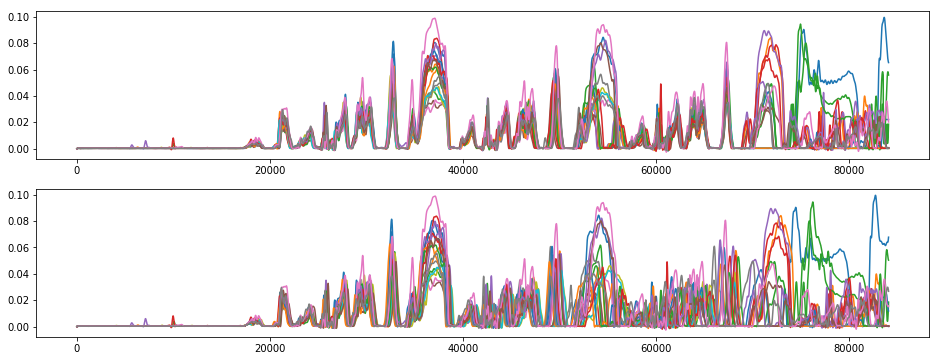

In [37]:
plt.figure(figsize=(16, 6))
plt.subplot(2, 1, 1)
for signal in data:
    plt.plot(signal)
plt.subplot(2, 1, 2)
for signal in tutor_amp_envelope:
    plt.plot(signal)
plt.show()

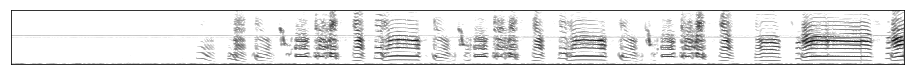

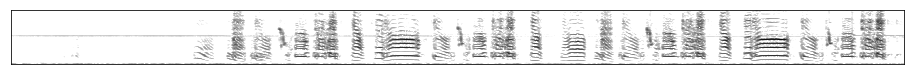

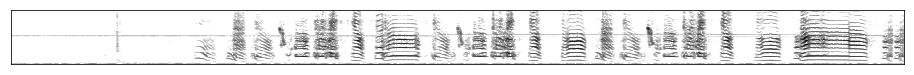

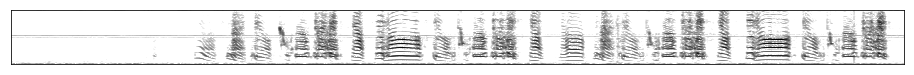

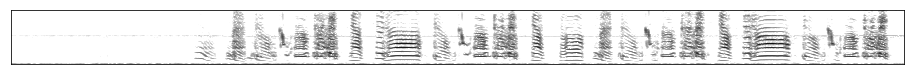

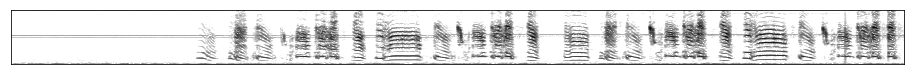

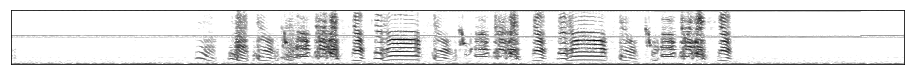

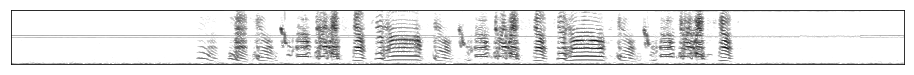

In [49]:
fitted_signals = tutor_timewarped.transform(cut_analogsignals[:, :, None])
for signal in fitted_signals[:8, :, 0]:
    fig, ax = plt.subplots(figsize=(16, 1))
    t, f, s, _ = spectrogram(signal - np.mean(signal), fs, 5000, 50.0, min_freq=0, max_freq=10000, nstd=6)
    plot_spectrogram(t, f, s, colormap="gray_r", ax=ax, colorbar=False)
    plt.ylabel("")
    plt.xlabel("")
    plt.yticks([])
    plt.show()

In [51]:
spike_times = multiseg.spike_times(unit=11)
warped_spike_times = tutor_timewarped.convert_times(spike_times)

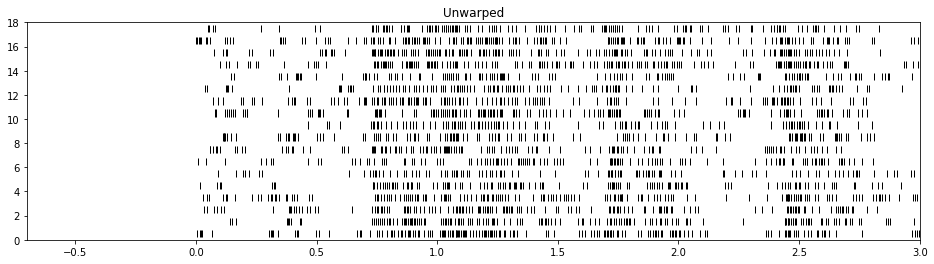

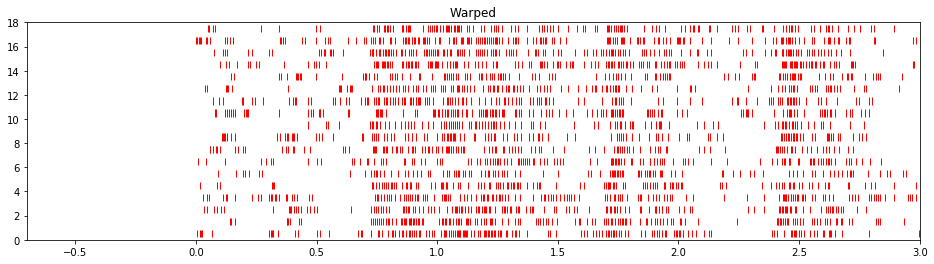

In [64]:
plt.figure(figsize=(16, 4))
multiseg.plotter.plot_raster(11)
plt.xlim(-.7, 3.0)
plt.title("Unwarped")
plt.show()

plt.figure(figsize=(16, 4))
raster.plot(warped_spike_times, color="Red")
plt.xlim(-.7, 3.0)
plt.title("Warped")
plt.show()

## Response to BOS

Onsets aligned, lots of variability in syllable timing though

* Spikes convolved with gaussian with width std=0.4ms

* N=24 songs

Something wrong is happening with the spike rasters


In [66]:
alignBOS = [14, 15, 23, 24, 26,28,29,30,32, 34, 35, 36, 37, 38, 39, 41, 42, 43, 44, 45, 47, 48, 49, 55]
print len(alignBOS)

24


again, compute offsets to realign

In [67]:
multiseg_bos = MultiSegment(np.array(block.segments)[alignBOS])
print multiseg_bos

MultiSegment with 24 Segments, 13 Units, t_start=-0.0s, t_stop=3.57116s
{'vocalization_type': 'unknown', 'sound_type': 'live', 'vocalizer': 'unknown', 'playback_file': None}


In [69]:
fs = np.round(multiseg_bos.segments[0].analogsignals[0].sampling_rate.item())
times, analogsignals = zip(*[multiseg_bos.get_analogsignal(s, 0, channel=0)[:2] for s in multiseg_bos.segments])
minlen = np.min([s.size for s in analogsignals])
cut_analogsignals = np.array([s[:minlen] for s in analogsignals])

In [70]:
sigs = np.zeros((len(analogsignals), minlen))
for i, signal in enumerate(analogsignals):
    signal = np.copy(signal)
    signal -= np.mean(signal)
    signal[:] = highpass_filter(signal, fs, 2000)
    signal[:] = np.abs(lowpass_filter(signal, fs, 4800))
    signal[:] = lowpass_filter(signal, fs, 100)
    sigs[i, :minlen] = lowpass_filter(signal, fs, 100)[:minlen]

In [71]:
bos_amp_envelope = np.copy(sigs)

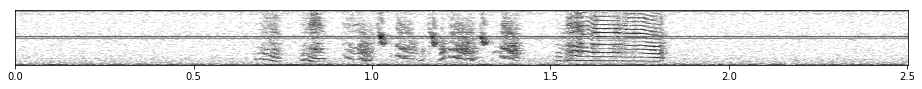

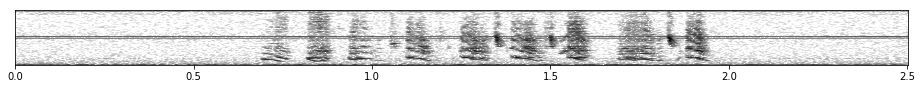

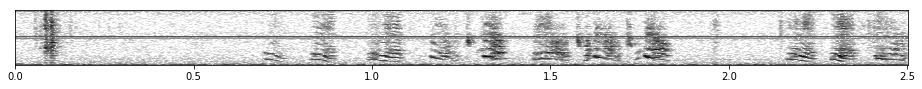

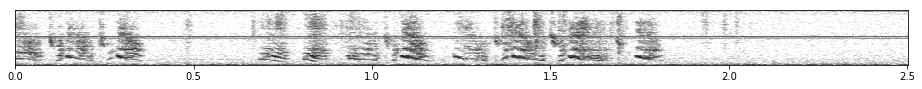

In [72]:
for signal in cut_analogsignals[:4]:
    fig, ax = plt.subplots(figsize=(16, 1))
    t, f, s, _ = spectrogram(signal - np.mean(signal), fs, 5000, 50.0, min_freq=0, max_freq=10000, nstd=6)
    plot_spectrogram(t, f, s, colormap="gray_r", ax=ax, colorbar=False)
    plt.ylabel("")
    plt.xlabel("")
    plt.yticks([])
    plt.show()

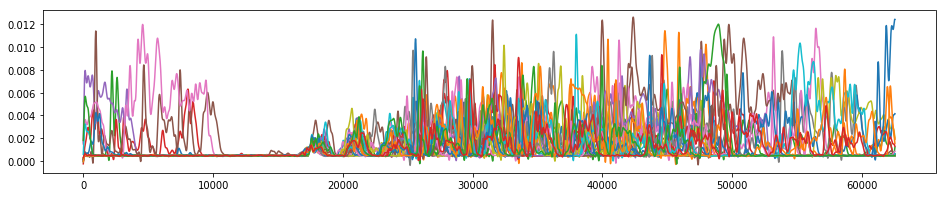

In [73]:
plt.figure(figsize=(16, 3))
for signal in bos_amp_envelope:
    plt.plot(signal)
plt.show()

In [74]:
bos_timewarped = WindowedTimeWarp(
    n_components=1,
    warptype="affine",
    warpinit="zero",
    warp_regularizer=curvature(scale=0.00001, power=1),
    time_regularizer=curvature(scale=0.00001, power=1, axis=0)
)

In [103]:
bos_amp_fitted = bos_timewarped.fit_transform(bos_amp_envelope[:, :, None], 40000, 20000, lr=2e-2, niter=iters)

100%|██████████| 100/100 [00:03<00:00, 29.16it/s]


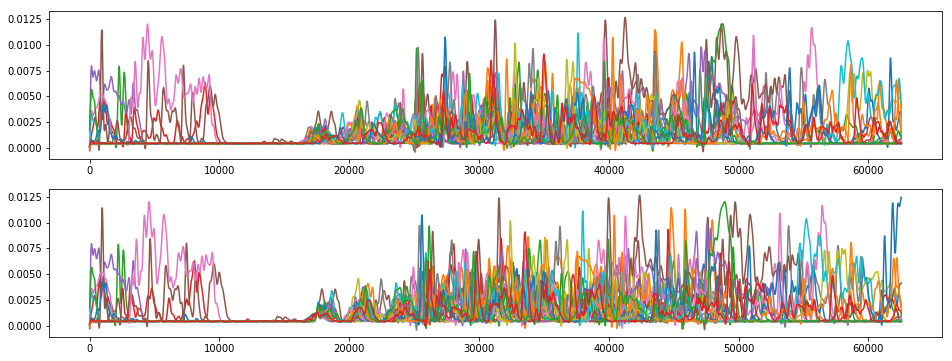

In [104]:
plt.figure(figsize=(16, 6))
plt.subplot(2, 1, 1)
for signal in bos_amp_fitted:
    plt.plot(signal)
plt.subplot(2, 1, 2)
for signal in bos_amp_envelope:
    plt.plot(signal)
plt.show()

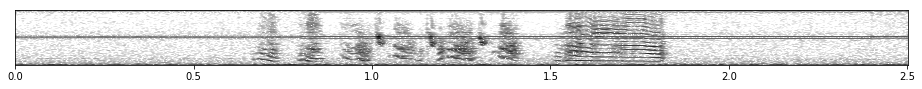

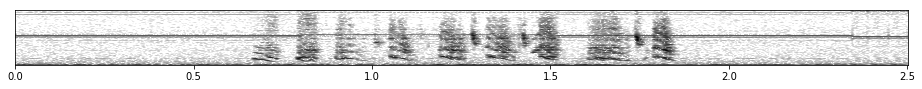

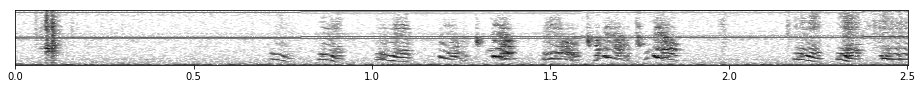

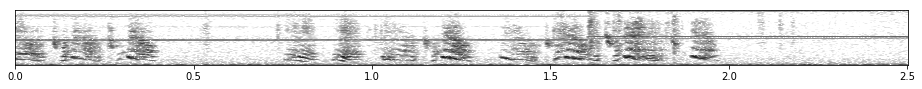

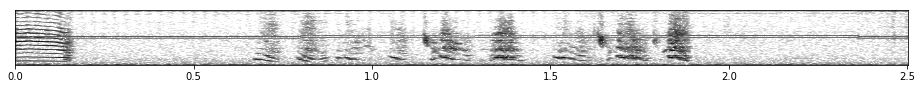

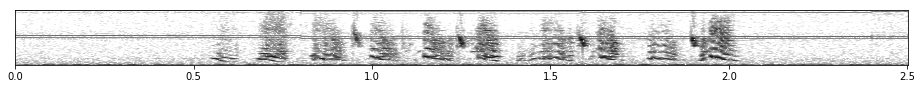

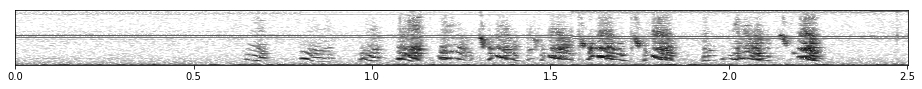

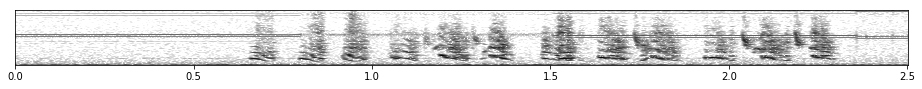

In [105]:
fitted_signals = bos_timewarped.transform(cut_analogsignals[:, :, None])
for signal in fitted_signals[:8, :, 0]:
    fig, ax = plt.subplots(figsize=(16, 1))
    t, f, s, _ = spectrogram(signal - np.mean(signal), fs, 5000, 50.0, min_freq=0, max_freq=10000, nstd=6)
    plot_spectrogram(t, f, s, colormap="gray_r", ax=ax, colorbar=False)
    plt.ylabel("")
    plt.xlabel("")
    plt.yticks([])
    plt.show()

In [106]:
spike_times = multiseg_bos.spike_times(unit=11)
warped_spike_times = bos_timewarped.convert_times(spike_times)

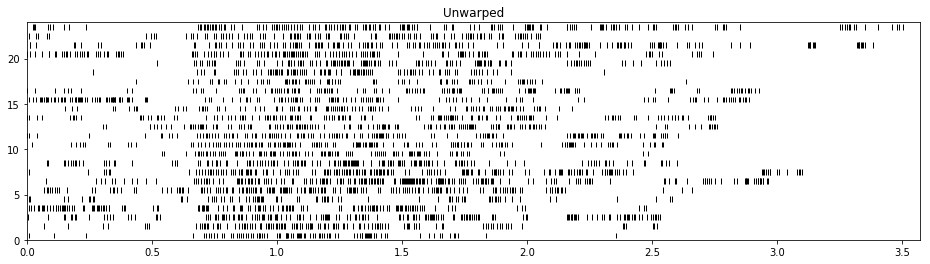

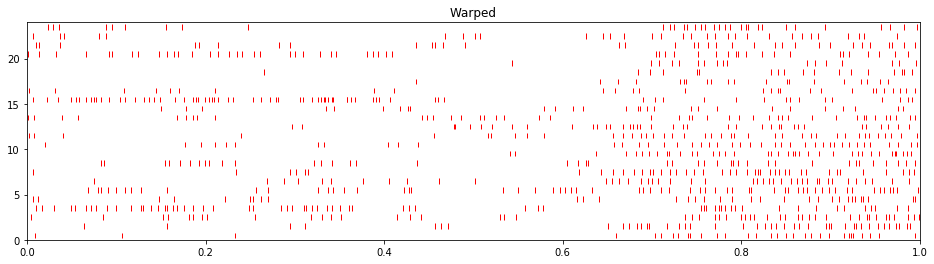

In [107]:
plt.figure(figsize=(16, 4))
multiseg_bos.plotter.plot_raster(11)
plt.title("Unwarped")
plt.show()

plt.figure(figsize=(16, 4))
raster.plot(warped_spike_times, color="Red")
plt.title("Warped")
plt.show()